# 01 · Data pipeline

This notebook builds all the data the project uses.

1. **Evaluation sets** from Lichess puzzles: a 1,000-puzzle **test set** and a 200-puzzle **dev set**, with equal numbers of puzzles in each difficulty band.
2. **Training examples** from Lichess games between strong players (2000+ ELO!). Each example is a board position and the move that was played there.
3. No training position may also appear in the evaluation sets (**leakage check**).
4. A **train / validation split** by game.

All settings come from `configs/data.yaml`. Downloads (about 1.9 GB) go to `data/raw/` and are reused on later runs.

**Outputs**
- `data/eval/`: test and dev puzzles (committed to GitHub)
- `data/processed/`: training data (not committed; rebuilt by this notebook)
- `results/data_stats.json`: dataset statistics

In [1]:
import json

import chess
import chess.svg
import pandas as pd
import yaml
from IPython.display import SVG, display

from chesslm.config import REPO_ROOT, load_config
from chesslm import data, plots

cfg = load_config("data")
SEED = cfg["seed"]
FIGURES = REPO_ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(yaml.safe_dump(cfg, sort_keys=False))

seed: 42
puzzles:
  repo: Lichess/chess-puzzles
  revision: 461725966ea46898ec6481372a6326de3281bfbd
  files:
  - data/train-00000-of-00003.parquet
  - data/train-00001-of-00003.parquet
  - data/train-00002-of-00003.parquet
  rating_band_edges:
  - 1200
  - 1800
  - 2400
  test_size: 1000
  dev_size: 200
games:
  repo: Lichess/standard-chess-games
  revision: de4e636eddf568a9394cc01fb0b9e1da04a6babf
  files:
  - data/year=2025/month=09/train-00000-of-00062.parquet
  min_elo: 2000
  exclude_bots: true
  min_base_time_seconds: 180
  termination: Normal
  min_moves: 20
  max_games: 50000
positions:
  per_game: 3
  skip_opening_moves: 5
  val_fraction: 0.05



## Part 1 · Puzzles → evaluation sets

Each Lichess puzzle has a starting position (`FEN`) and a list of moves (`Moves`, in UCI notation). The format has a catch:

- The stored FEN is the position **before the opponent's move**.
- The **first** move in `Moves` is the opponent's move. Playing it gives the position the solver actually faces.
- The **second** move is the correct answer.

Reading this wrong would make every puzzle score meaningless, so `data.puzzle_to_example` handles it, and `tests/test_data.py` tests it for both White and Black solvers.

In [2]:
puzzles = data.load_puzzles(cfg["puzzles"])
print(f"{len(puzzles):,} puzzles in the database\n")
print(puzzles.band.value_counts().reindex(["<1200", "1200-1800", "1800-2400", "2400+"]).to_string())

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  295MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  295MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  295MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

6,157,341 puzzles in the database

band
<1200        2283229
1200-1800    2132233
1800-2400    1388391
2400+         353488


**One puzzle, step by step.** Below, the stored position, and then the position after the opponent's move. The arrow shows the correct answer.

Puzzle 00008, rating 1811, moves: f2g3 e6e7 b2b1 b3c1 b1c1 h6c1
Stored position: Black to move; the opponent plays Bxg3


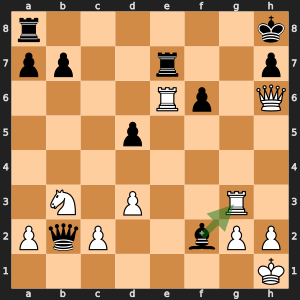

Solver's position: White to move; correct answer Rxe7 (e6e7)


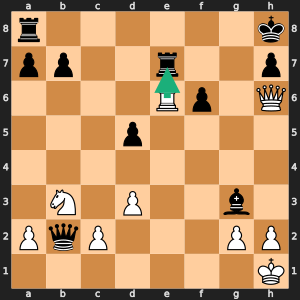

In [3]:
example = puzzles.iloc[0]
print(f"Puzzle {example.PuzzleId}, rating {example.Rating}, moves: {example.Moves}")

stored = chess.Board(example.FEN)
opponent_move = chess.Move.from_uci(example.Moves.split()[0])
print(f"Stored position: {'White' if stored.turn else 'Black'} to move; the opponent plays {stored.san(opponent_move)}")
display(SVG(chess.svg.board(stored, arrows=[(opponent_move.from_square, opponent_move.to_square)], size=300)))

solver_fen, answer = data.puzzle_to_example(example.FEN, example.Moves)
solver = chess.Board(solver_fen)
answer_move = chess.Move.from_uci(answer)
print(f"Solver's position: {'White' if solver.turn else 'Black'} to move; correct answer {solver.san(answer_move)} ({answer})")
display(SVG(chess.svg.board(solver, arrows=[chess.svg.Arrow(answer_move.from_square, answer_move.to_square, color="#1baf7a")], size=300)))

**Sampling the evaluation sets.** We draw the same number of puzzles from each rating band (250 per band for test, 50 for dev), using a fixed seed. Equal bands let us report accuracy per difficulty level, not just overall. Test and dev never share a puzzle.

In [4]:
test, dev = data.sample_eval_sets(puzzles, cfg["puzzles"], SEED)
assert not set(test.puzzle_id) & set(dev.puzzle_id), "test and dev share a puzzle"

data.EVAL_DIR.mkdir(parents=True, exist_ok=True)
test.to_csv(data.EVAL_DIR / "puzzles_test.csv", index=False)
dev.to_csv(data.EVAL_DIR / "puzzles_dev.csv", index=False)

summary = pd.DataFrame({"test": test.band.value_counts(), "dev": dev.band.value_counts()}).reindex(
    ["<1200", "1200-1800", "1800-2400", "2400+"])
summary.loc["total"] = summary.sum()
print(summary.to_string())
print(f"\nMate-in-1 puzzles (any checkmating move counts): test {test.mate_in_1.sum()}, dev {dev.mate_in_1.sum()}")

           test  dev
band                
<1200       250   50
1200-1800   250   50
1800-2400   250   50
2400+       250   50
total      1000  200

Mate-in-1 puzzles (any checkmating move counts): test 110, dev 21


,puzzle_id,fen,history_uci,history_san,answer_uci,answer_san,rating,band,mate_in_1,themes
0,H3pq9,3kr3/1R5R/1p2rp2/p7/8/1p5P/5PP1/6K1 w - - 0 34,b4b3,b3,b7b8,Rb8#,1518,1200-1800,True,endgame mate mateIn1 oneMove rookEndgame
1,13R0S,8/p5k1/1p3p1p/4pPpP/3pP3/3P4/PP3P2/2K5 w - - 0 33,c5d4,cxd4,c1c2,Kc2,1662,1200-1800,False,crushing endgame pawnEndgame veryLong
2,7vXxN,6r1/1p3p1k/2p1pQ1p/p7/3PR3/6P1/2q2PKP/8 w - - ...,c1c2,Qxc2,f6f7,Qxf7+,1586,1200-1800,False,crushing endgame long


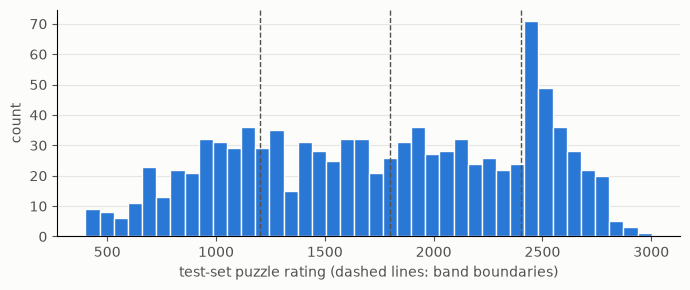

In [5]:
plots.histogram(test.rating, "test-set puzzle rating (dashed lines: band boundaries)",
                FIGURES / "test_puzzle_ratings.png", edges=cfg["puzzles"]["rating_band_edges"]);
test.head(3)

## Part 2 · Games → training examples

We use one file of Lichess games from September 2025 (about 1.4 million games) and keep only games that pass every filter:

- **both players rated 2000 or higher**, so the moves we train on are strong
- **no bot accounts**: Lichess bots are chess engines, and we want to learn from human play
- **not bullet** (at least 3 minutes per player), since very fast games contain more blunders
- **ended normally** (checkmate, resignation, or draw), not on time or by abandonment
- **at least 20 moves long**

The table shows how many games remain after each filter.

In [6]:
games, funnel = data.load_games(cfg["games"])
positions, n_games_used = data.build_positions(games, cfg["games"], cfg["positions"], SEED)
funnel[f"at least {cfg['games']['min_moves']} moves (first {cfg['games']['max_games']:,} kept)"] = n_games_used

print(pd.Series(funnel, name="games").map("{:,}".format).to_string())

data/year=2025/month=09/train-00000-of-0(…): reconstructing file:   0%|          |  0.00B / 1.00GB            

data/year=2025/month=09/train-00000-of-0(…): downloading bytes:           |  0.00B            

games read                               1,404,031
both players rated 2000+                   245,522
no bot accounts                            242,573
not bullet (base time >= 180s)              92,501
termination = Normal                        70,904
at least 20 moves (first 50,000 kept)       50,000


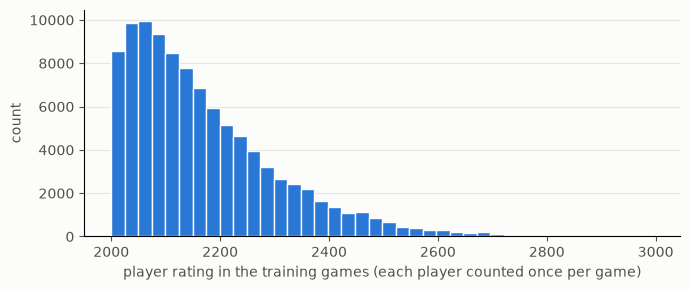

In [7]:
one_row_per_game = positions.drop_duplicates("game_id")
plots.histogram(pd.concat([one_row_per_game.white_elo, one_row_per_game.black_elo]),
                "player rating in the training games (each player counted once per game)",
                FIGURES / "training_player_ratings.png");

From each game we sample **3 positions** (`positions.per_game` in the config), skipping the first 5 moves (openings are mostly memorized sequences). Each example stores the position as a FEN, every earlier move (for the optional move-history prompt), and the move actually played, in both UCI and SAN notation.

Three examples:

Game nv1aCL1G, move 59, Black to play
  FEN:          8/8/4pR2/5b2/PK3k2/8/7r/8 b - - 0 59
  recent moves: h3f5 f2f4 g2f3 a4b4 f3f4 a3a4
  move played:  Rb2+ (SAN) = h2b2 (UCI)


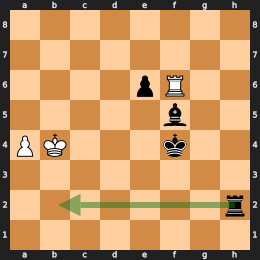

Game ixghEFUG, move 17, Black to play
  FEN:          r2q1r2/1b2npkp/p3p1p1/1p1pPn2/1P1P4/P2B1N2/1B1Q1PPP/2R2RK1 b - - 4 17
  recent moves: b7b5 b2b4 c6e7 c3b2 c8b7 a1c1
  move played:  Rc8 (SAN) = a8c8 (UCI)


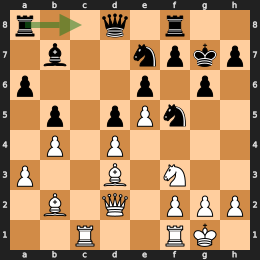

Game ubSZynZe, move 26, Black to play
  FEN:          r2r1n2/pbq3k1/2p2N1p/1pnp4/4PR2/1P4QP/PRP3B1/7K b - - 0 26
  recent moves: g8g7 f1f4 h4g3 h2h1 d6d5 e3g3
  move played:  Ng6 (SAN) = f8g6 (UCI)


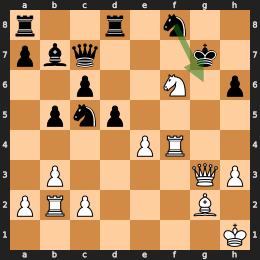

In [8]:
for row in positions.sample(3, random_state=SEED).itertuples():
    board = chess.Board(row.fen)
    move = chess.Move.from_uci(row.move_uci)
    last_moves = row.history_uci.split()[-6:]
    print(f"Game {row.game_id}, move {row.ply // 2 + 1}, {'White' if board.turn else 'Black'} to play")
    print(f"  FEN:          {row.fen}")
    print(f"  recent moves: {' '.join(last_moves)}")
    print(f"  move played:  {row.move_san} (SAN) = {row.move_uci} (UCI)")
    display(SVG(chess.svg.board(board, arrows=[(move.from_square, move.to_square)], size=260)))

## Part 3 · Leakage check

If a training position were identical to a test puzzle, the model could memorize the answer, and its score would measure memory rather than skill. We compare positions by their first four FEN fields: pieces, side to move, castling rights, and en passant. The move counters are ignored, since they don't change the position. Any training position that matches a test or dev puzzle is removed.

In [9]:
eval_fens = pd.concat([test.fen, dev.fen])
n_before = len(positions)
positions, n_removed = data.remove_overlap(positions, eval_fens)
print(f"Training positions before: {n_before:,}")
print(f"Removed (also in test/dev): {n_removed:,}")

eval_keys = set(eval_fens.map(data.normalize_fen))
remaining_overlap = positions.fen.map(data.normalize_fen).isin(eval_keys).sum()
print(f"Overlap after removal:     {remaining_overlap}")
assert remaining_overlap == 0

Training positions before: 150,000
Removed (also in test/dev): 0
Overlap after removal:     0


## Part 4 · Train / validation split

We hold out 5% of **games** for validation, which we use to watch for overfitting during training. The split is by game, not by position: positions from the same game are similar, and splitting them across both sides would make validation look better than it is.

In [10]:
train, val = data.split_by_game(positions, cfg["positions"]["val_fraction"], SEED)
assert set(train.game_id).isdisjoint(val.game_id)

data.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train.to_parquet(data.PROCESSED_DIR / "train.parquet", index=False)
val.to_parquet(data.PROCESSED_DIR / "val.parquet", index=False)

print(f"train: {len(train):,} positions from {train.game_id.nunique():,} games")
print(f"val:   {len(val):,} positions from {val.game_id.nunique():,} games")

train: 142,500 positions from 47,500 games
val:   7,500 positions from 2,500 games


## Part 5 · Save dataset statistics

These numbers go into `results/data_stats.json`, which is committed, so the team can cite them.

In [11]:
stats = {
    "games_source": f"{cfg['games']['repo']} @ {cfg['games']['revision'][:7]}: {', '.join(cfg['games']['files'])}",
    "puzzles_source": f"{cfg['puzzles']['repo']} @ {cfg['puzzles']['revision'][:7]}",
    "game_filter_funnel": {k: int(v) for k, v in funnel.items()},
    "positions_sampled": n_before,
    "positions_removed_overlap": n_removed,
    "train_positions": len(train),
    "train_games": int(train.game_id.nunique()),
    "val_positions": len(val),
    "val_games": int(val.game_id.nunique()),
    "puzzles_in_database": len(puzzles),
    "test_puzzles_per_band": test.band.value_counts().sort_index().to_dict(),
    "dev_puzzles_per_band": dev.band.value_counts().sort_index().to_dict(),
    "test_mate_in_1": int(test.mate_in_1.sum()),
    "seed": SEED,
}
(REPO_ROOT / "results").mkdir(exist_ok=True)
with open(REPO_ROOT / "results" / "data_stats.json", "w") as f:
    json.dump(stats, f, indent=2)
print(json.dumps(stats, indent=2))

{
  "games_source": "Lichess/standard-chess-games @ de4e636: data/year=2025/month=09/train-00000-of-00062.parquet",
  "puzzles_source": "Lichess/chess-puzzles @ 4617259",
  "game_filter_funnel": {
    "games read": 1404031,
    "both players rated 2000+": 245522,
    "no bot accounts": 242573,
    "not bullet (base time >= 180s)": 92501,
    "termination = Normal": 70904,
    "at least 20 moves (first 50,000 kept)": 50000
  },
  "positions_sampled": 150000,
  "positions_removed_overlap": 0,
  "train_positions": 142500,
  "train_games": 47500,
  "val_positions": 7500,
  "val_games": 2500,
  "puzzles_in_database": 6157341,
  "test_puzzles_per_band": {
    "1200-1800": 250,
    "1800-2400": 250,
    "2400+": 250,
    "<1200": 250
  },
  "dev_puzzles_per_band": {
    "1200-1800": 50,
    "1800-2400": 50,
    "2400+": 50,
    "<1200": 50
  },
  "test_mate_in_1": 110,
  "seed": 42
}


## Part 6 · What the model sees

`src/chesslm/prompts.py` turns a position into the chat message Gemma receives. Its settings are in `configs/prompt.yaml`, which training and evaluation both read, so the question is always asked the same way. By default the prompt contains the board as a FEN, whose turn it is, and an instruction to answer with one move in UCI notation.

Below are three training examples: the full prompt (including Gemma's turn markers) and the answer the model is trained to give.

In [12]:
from transformers import AutoTokenizer

from chesslm.prompts import build_prompt, move_to_text, parse_move

prompt_cfg = load_config("prompt")
tokenizer = AutoTokenizer.from_pretrained(load_config("sft")["model"]["id"])
print("Prompt settings:", prompt_cfg, "\n")

for row in train.sample(3, random_state=SEED).to_dict("records"):
    print(build_prompt(tokenizer, row, prompt_cfg), end="")
    print(f"→ answer: {row['move_' + prompt_cfg['notation']]}")
    print("-" * 70)

Prompt settings: {'notation': 'uci', 'history_moves': 0, 'show_legal_moves': False} 

<bos><|turn>user
Chess position (FEN): 6r1/1pp5/p3Pk1p/5P2/2p2K1N/P1P5/1P5P/6r1 w - - 3 35
White to move.
Reply with the best move in UCI notation (for example e2e4) and nothing else.<turn|>
<|turn>model
→ answer: h4f3
----------------------------------------------------------------------
<bos><|turn>user
Chess position (FEN): 2r1rk2/1b4pQ/p6p/5B2/3p1q2/PN4bP/2P5/R5K1 w - - 4 35
White to move.
Reply with the best move in UCI notation (for example e2e4) and nothing else.<turn|>
<|turn>model
→ answer: h7h8
----------------------------------------------------------------------
<bos><|turn>user
Chess position (FEN): rnbq1rk1/ppp1ppbp/3p1npB/8/3P4/2N5/PPPQPPPP/R3KBNR w KQ - 4 6
White to move.
Reply with the best move in UCI notation (for example e2e4) and nothing else.<turn|>
<|turn>model
→ answer: f2f3
----------------------------------------------------------------------


**Prompt length for each option.** Longer prompts cost more memory and time in training. The SFT config allows 256 tokens per example (prompt plus answer). Here is how long the prompt gets under each option, measured on 500 training positions.

In [13]:
options = {
    "board only (default)": {**prompt_cfg, "history_moves": 0, "show_legal_moves": False},
    "board + last move": {**prompt_cfg, "history_moves": 1, "show_legal_moves": False},
    "board + legal moves": {**prompt_cfg, "history_moves": 0, "show_legal_moves": True},
}
rows = train.sample(500, random_state=SEED).to_dict("records")
lengths = {}
for name, cfg_option in options.items():
    n_tokens = [len(tokenizer(build_prompt(tokenizer, r, cfg_option), add_special_tokens=False)["input_ids"]) for r in rows]
    lengths[name] = pd.Series(n_tokens).describe()[["mean", "max"]].round(0)
print(pd.DataFrame(lengths).T.astype(int).to_string())

                      mean  max
board only (default)    90  102
board + last move       98  110
board + legal moves    224  323


**Reading the answer back.** `parse_move` finds the first move in the model's reply and checks it against the position:
- **legal**: a move that is allowed in the position
- **illegal**: something that looks like a move but is not allowed (for example, a piece that can't reach that square)
- **unparseable**: no move at all

It accepts both UCI and SAN, whichever the model writes. Some example replies for the starting position:

In [14]:
board = chess.Board()
for reply in ["e2e4", "The best move is Nf3.", "**d4**", "e2e5", "Nf6", "I would play aggressively."]:
    move, reason = parse_move(reply, board)
    shown = f"{move_to_text(board, move, 'uci')} / {move_to_text(board, move, 'san')}" if move else "-"
    print(f"{reply!r:30} -> {reason:12} {shown}")

'e2e4'                         -> legal        e2e4 / e4
'The best move is Nf3.'        -> legal        g1f3 / Nf3
'**d4**'                       -> legal        d2d4 / d4
'e2e5'                         -> illegal      -
'Nf6'                          -> illegal      -
'I would play aggressively.'   -> unparseable  -


## Summary

- The test and dev puzzle sets are fixed and saved in `data/eval/`. Every model is graded on exactly these puzzles.
- The training and validation positions are saved in `data/processed/`.
- No training position appears in the evaluation sets.
- Every position can be turned into a prompt, and the model's reply can be read back as a legal, illegal, or unparseable move.

**Next:** measuring the base model on the dev and test puzzles (`02_eval_base_model.ipynb`).